# High-ε particle in a rectangular waveguide

`pip install git+https://github.com/dyed-eye/sceptre matplotlib` (the `sceptre` on PyPI is an unrelated AWS tool).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import sceptre
from sceptre import Cylinder, Solver, Structure, Waveguide

sceptre.set_blas_threads(sceptre.recommended_blas_threads())

In [2]:
wg = Waveguide(a=22.86e-3, b=10.16e-3)  # cross-section, meters
particle = Cylinder(cx=wg.a / 2, cy=wg.b / 2, r=2e-3, z1=0.0, z2=2e-3, eps=70.0)
structure = Structure(wg, shapes=[particle])

Wall-aligned boxes: `Box` + `"li"`; Li's rules are exact there, and `asr=AsrConfig()` helps when there are few edges. Curved boundaries at high ε: `factorization="nvf"`.

nvf = normal-vector-field (Popov & Nevière (JOSA A 17, 1773, 2000))

Why NVF and not ASR for curved shapes. At a high-ε boundary the normal component of D and the tangential E are continuous, so ε has to be inverted along the normal and used directly along the tangent. On a staircase, `li` and ASR apply these rules along x and y, which is wrong wherever the boundary is tilted. ASR only adds resolution near edges, and its compression intervals cannot be shorter than 4a/M, so on a many-step staircase it thins to almost no compression and convergence stays close to plain Li (~1/N). NVF applies the rules along the actual boundary normal, which removes the error instead of resolving it. On an ε = 80 disk, NVF at N = 20 lands 0.8 MHz from the FEM/VNA line; plain Li at N = 24 is still 92 MHz off.

`M`, `N` are the truncation orders along x and y. Increase them until the line stops moving.

In [3]:
solver = Solver(structure, M=12, N=12, factorization="nvf")
te10 = ("TE", 1, 0)
freqs = np.linspace(10.5e9, 12.0e9, 61)

s11, s21 = [], []
for f in freqs:
    res = solver.smatrix(f)
    s11.append(res.coeff(1, te10, 1, te10))
    s21.append(res.coeff(2, te10, 1, te10))
s11, s21 = np.abs(s11), np.abs(s21)

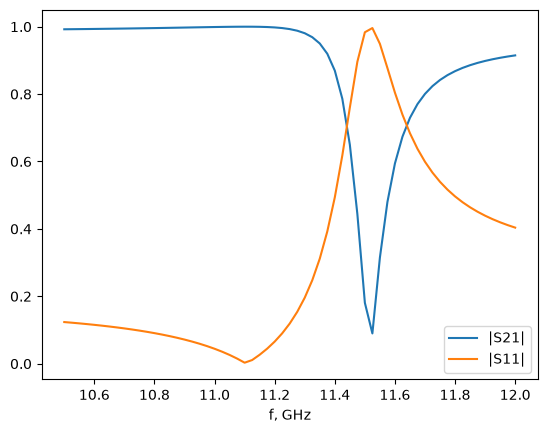

In [4]:
plt.plot(freqs / 1e9, s21, label="|S21|")
plt.plot(freqs / 1e9, s11, label="|S11|")
plt.xlabel("f, GHz")
plt.legend();

Lossless check: every column of the port S-matrix has unit norm.

In [5]:
P = solver.smatrix(freqs[np.argmin(s21)]).port_smatrix()
np.sum(np.abs(P) ** 2, axis=0)

array([1., 1.])

## Custom cross-section

Any `Shape` subclass with a signed-distance `level_set` (negative inside) and a `bbox` works with `nvf`, extruded along z. The default staircase allows one material interval per x-strip; override `staircase` for sections that are not convex in y.

In [6]:
from matplotlib.path import Path

from sceptre import Shape


class Polygon(Shape):
    def __init__(self, vertices, z1, z2, eps, k=64):
        super().__init__(z1, z2, eps, k)
        self.vertices = np.asarray(vertices, dtype=float)
        self.path = Path(self.vertices)

    def level_set(self, x, y):
        p = np.stack(np.broadcast_arrays(x, y), axis=-1).astype(float)[..., None, :]
        a = self.vertices
        ab = np.roll(a, -1, axis=0) - a
        t = np.clip(((p - a) * ab).sum(-1) / (ab**2).sum(-1), 0.0, 1.0)
        dist = np.linalg.norm(p - (a + t[..., None] * ab), axis=-1).min(-1)
        inside = self.path.contains_points(p.reshape(-1, 2)).reshape(dist.shape)
        return np.where(inside, -dist, dist)

    @property
    def bbox(self):
        (x1, y1), (x2, y2) = self.vertices.min(axis=0), self.vertices.max(axis=0)
        return x1, x2, y1, y2

In [7]:
def te10_s21(solver, freqs):
    te10 = ("TE", 1, 0)
    return np.abs([solver.smatrix(f).coeff(2, te10, 1, te10) for f in freqs])

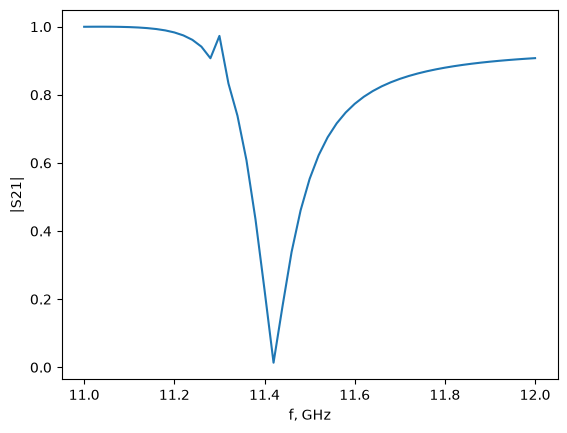

In [8]:
mm = 1e-3
outline = (
    np.array([(-2.2, -1.6), (2.0, -1.8), (2.4, 0.6), (0.2, 2.2), (-2.0, 1.2)]) * mm
)
pentagon = Polygon(outline + [wg.a / 2, wg.b / 2], z1=0.0, z2=2 * mm, eps=70.0)

solver = Solver(Structure(wg, shapes=[pentagon]), M=12, N=12, factorization="nvf")
freqs = np.linspace(11.0e9, 12.0e9, 51)
plt.plot(freqs / 1e9, te10_s21(solver, freqs))
plt.xlabel("f, GHz")
plt.ylabel("|S21|");

## 3D model

`pip install trimesh rtree`. trimesh is only for the STL: it reads the file and tests which voxel centres are inside the mesh (rtree is what that test needs). The solver and the cells above don't use it.

The mesh is voxelized into z-slices of ε grids (`Structure.from_segments`). Grids take the scalar `li` factorization (NVF needs `Shape` normals), so check convergence in `M`, `N` and in `nxy`, `nz`.

In [9]:
import trimesh

from sceptre import CrossSection, Segment

mesh = trimesh.creation.icosphere(
    subdivisions=3, radius=2.0
)  # or trimesh.load("model.stl")
mesh.apply_scale(mm)  # model units -> m
(x1, y1, z1), (x2, y2, z2) = mesh.bounds
mesh.apply_translation([wg.a / 2 - (x1 + x2) / 2, wg.b / 2 - (y1 + y2) / 2, -z1])

<trimesh.Trimesh(vertices.shape=(642, 3), faces.shape=(1280, 3))>

In [10]:
def voxelize(mesh, eps, nxy=24, nz=8):
    (x1, y1, z1), (x2, y2, z2) = mesh.bounds
    xe = np.unique(np.clip(np.r_[0.0, np.linspace(x1, x2, nxy + 1), wg.a], 0.0, wg.a))
    ye = np.unique(np.clip(np.r_[0.0, np.linspace(y1, y2, nxy + 1), wg.b], 0.0, wg.b))
    ze = np.linspace(z1, z2, nz + 1)
    X, Y = np.meshgrid((xe[1:] + xe[:-1]) / 2, (ye[1:] + ye[:-1]) / 2, indexing="ij")
    segments = []
    for za, zb in zip(ze[:-1], ze[1:], strict=True):
        points = np.column_stack([X.ravel(), Y.ravel(), np.full(X.size, (za + zb) / 2)])
        inside = mesh.contains(points).reshape(X.shape)
        cells = np.where(inside, eps, 1.0).astype(complex)
        segments.append(Segment(za, zb, CrossSection(xe, ye, cells)))
    return Structure.from_segments(wg, segments)

C:\tmp\ipykernel_32000\1220839709.py:1: UserWarning: permittivity contrast 70 is high: the plain Li factorization converges slowly here — consider Solver(..., asr=AsrConfig()) or verify convergence by increasing N.
  solver = Solver(voxelize(mesh, eps=70.0), M=12, N=12)


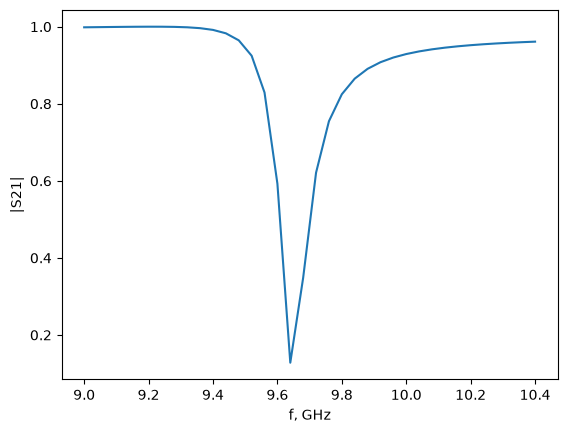

In [11]:
solver = Solver(voxelize(mesh, eps=70.0), M=12, N=12)
freqs = np.linspace(9.0e9, 10.4e9, 36)
plt.plot(freqs / 1e9, te10_s21(solver, freqs))
plt.xlabel("f, GHz")
plt.ylabel("|S21|");

## Geometry views

`show_mesh` draws the model in the guide: x along a, y along b, z is the propagation direction (TE10 has E along y). `show_sections` plots Re ε of each z-segment as the solver sees it, so it works for shapes and meshes alike.

In [12]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection


def show_mesh(mesh, pad=2 * mm):
    ax = plt.figure().add_subplot(projection="3d")
    ax.add_collection3d(
        Poly3DCollection(mesh.triangles / mm, alpha=0.5, edgecolor="k", linewidth=0.1)
    )
    a, b = wg.a / mm, wg.b / mm
    z1, z2 = (mesh.bounds[:, 2] + [-pad, pad]) / mm
    for x, y in [(0, 0), (a, 0), (a, b), (0, b)]:
        ax.plot([x, x], [y, y], [z1, z2], color="gray")
    for z in (z1, z2):
        ax.plot([0, a, a, 0, 0], [0, 0, b, b, 0], [z] * 5, color="gray")
    ax.set(
        xlim=(0, a),
        ylim=(0, b),
        zlim=(z1, z2),
        xlabel="x, mm",
        ylabel="y, mm",
        zlabel="z, mm",
    )
    ax.set_box_aspect((a, b, z2 - z1))


def show_sections(structure, ncols=4):
    segments = structure.segments()
    ncols = min(ncols, len(segments))
    nrows = -(-len(segments) // ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(3 * ncols, 1.6 * nrows), squeeze=False
    )
    for ax in axes.flat[len(segments) :]:
        ax.axis("off")
    for ax, seg in zip(axes.flat, segments, strict=False):
        cs = seg.cross_section
        ax.pcolormesh(cs.x_edges / mm, cs.y_edges / mm, cs.eps_cells.real.T)
        ax.set_aspect("equal")
        ax.set_title(f"z = {seg.z1 / mm:.2f}..{seg.z2 / mm:.2f} mm", fontsize=8)
    fig.tight_layout()

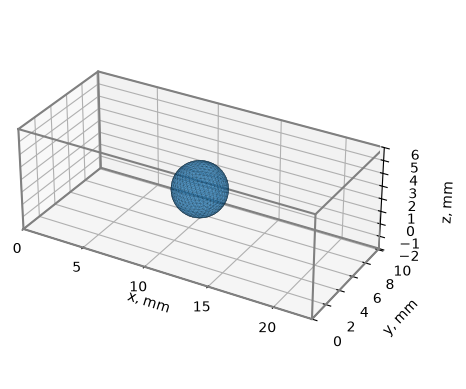

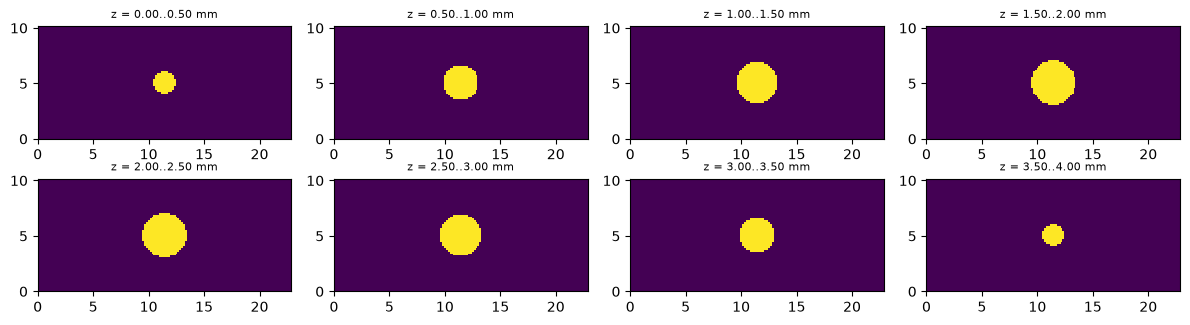

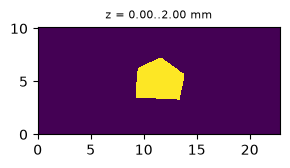

In [13]:
show_mesh(mesh)
show_sections(voxelize(mesh, eps=70.0))
show_sections(Structure(wg, shapes=[pentagon]))

## Re-orientation

Rotate after scaling and before centring, since centring reads `mesh.bounds`. Use rotations: swapping two axes mirrors the model, which for a chiral particle gives the other enantiomer.

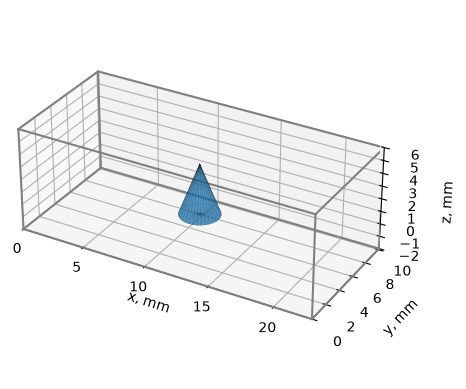

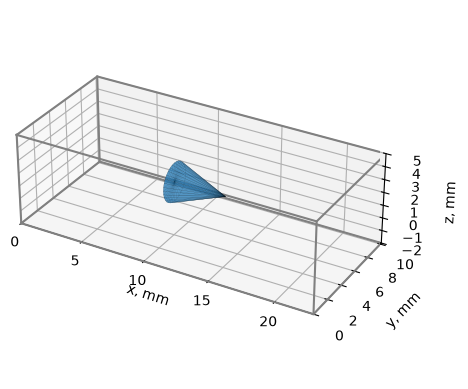

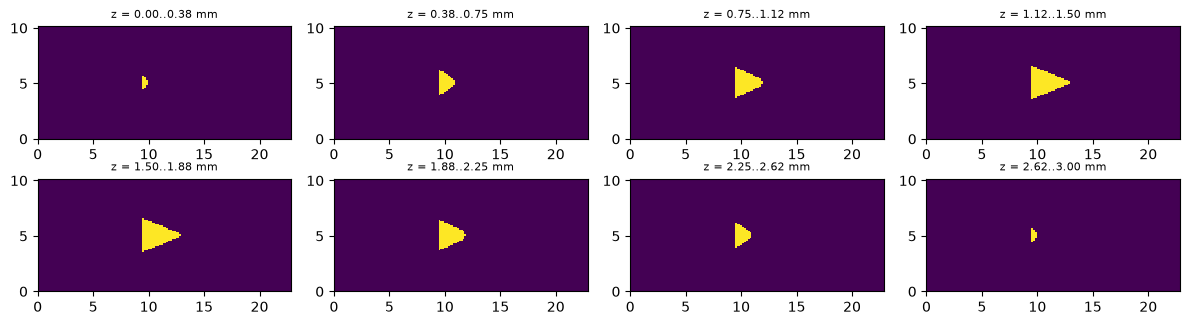

In [14]:
def center_in_guide(mesh):
    (x1, y1, z1), (x2, y2, z2) = mesh.bounds
    mesh.apply_translation([wg.a / 2 - (x1 + x2) / 2, wg.b / 2 - (y1 + y2) / 2, -z1])


cone = trimesh.creation.cone(radius=1.5, height=4.0)
cone.apply_scale(mm)
tilted = cone.copy()
tilted.apply_transform(
    trimesh.transformations.rotation_matrix(np.radians(90), [0, 1, 0])
)  # cone axis z -> x
center_in_guide(cone)
center_in_guide(tilted)

show_mesh(cone)
show_mesh(tilted)
show_sections(voxelize(tilted, eps=70.0))